In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/hr_cleaned.csv")

In [2]:
total_employees = len(df)

employees_left = (df["Attrition"] == "Yes").sum()

employees_stayed = (df["Attrition"] == "No").sum()

attrition_rate = (employees_left / total_employees) * 100

retention_rate = (employees_stayed / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print("Attrition Rate:", round(attrition_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12 %
Retention Rate: 83.88 %


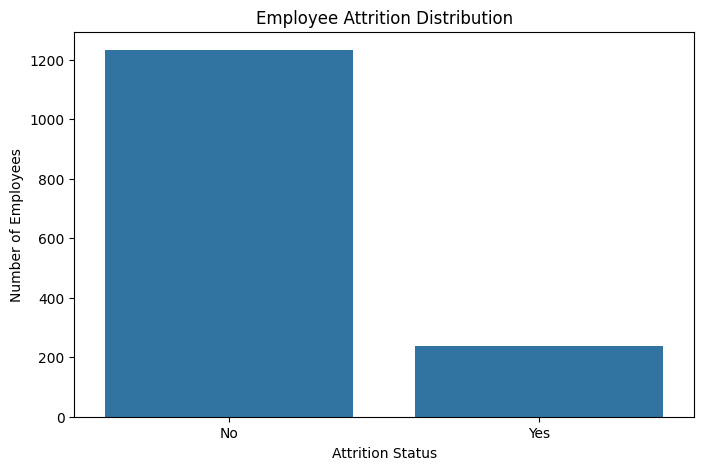

In [3]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Attrition",
    order=["No", "Yes"]
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")

plt.show()

In [4]:
department_analysis = df.groupby("Department").agg(
    Total_Employees=("EmployeeNumber", "count"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

department_analysis["Attrition_Rate"] = (
    department_analysis["Employees_Left"] /
    department_analysis["Total_Employees"]
) * 100

department_analysis = department_analysis.sort_values(
    by="Attrition_Rate",
    ascending=False
)

department_analysis

,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
Sales,446,92,20.627803
Human Resources,63,12,19.047619
Research & Development,961,133,13.839750


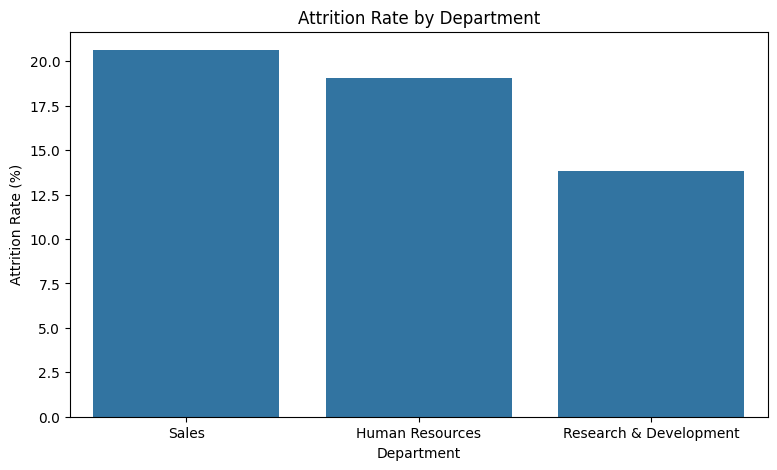

In [5]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=department_analysis.reset_index(),
    x="Department",
    y="Attrition_Rate"
)

plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.show()

In [6]:
overtime_analysis = df.groupby("OverTime").agg(
    Total_Employees=("EmployeeNumber", "count"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

overtime_analysis["Attrition_Rate"] = (
    overtime_analysis["Employees_Left"] /
    overtime_analysis["Total_Employees"]
) * 100

overtime_analysis

,Total_Employees,Employees_Left,Attrition_Rate
OverTime,,,
No,1054,110,10.436433
Yes,416,127,30.528846


In [7]:
satisfaction_analysis = df.groupby("JobSatisfaction").agg(
    Total_Employees=("EmployeeNumber", "count"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

satisfaction_analysis["Attrition_Rate"] = (
    satisfaction_analysis["Employees_Left"] /
    satisfaction_analysis["Total_Employees"]
) * 100

satisfaction_analysis

,Total_Employees,Employees_Left,Attrition_Rate
JobSatisfaction,,,
1,289,66,22.837370
2,280,46,16.428571
3,442,73,16.515837
4,459,52,11.328976


In [8]:
income_analysis = df.groupby("Attrition")["MonthlyIncome"].mean()

print(income_analysis)

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


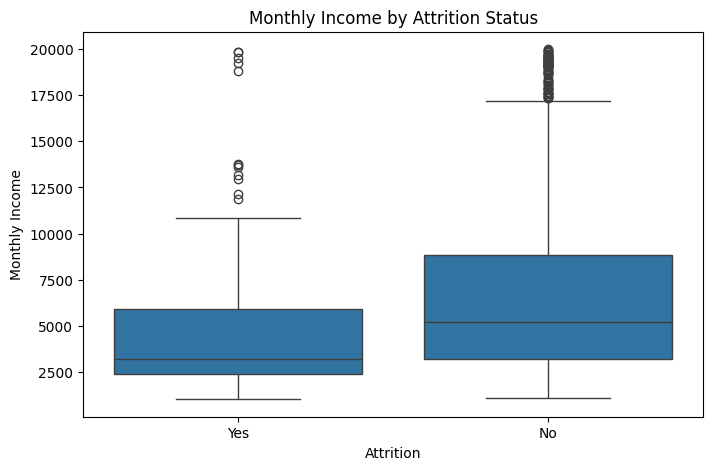

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income by Attrition Status")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

In [10]:
income_analysis = df.groupby("Attrition")["MonthlyIncome"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(income_analysis.round(2))

           count     mean  median   min    max
Attrition                                     
No          1233  6832.74  5204.0  1051  19999
Yes          237  4787.09  3202.0  1009  19859


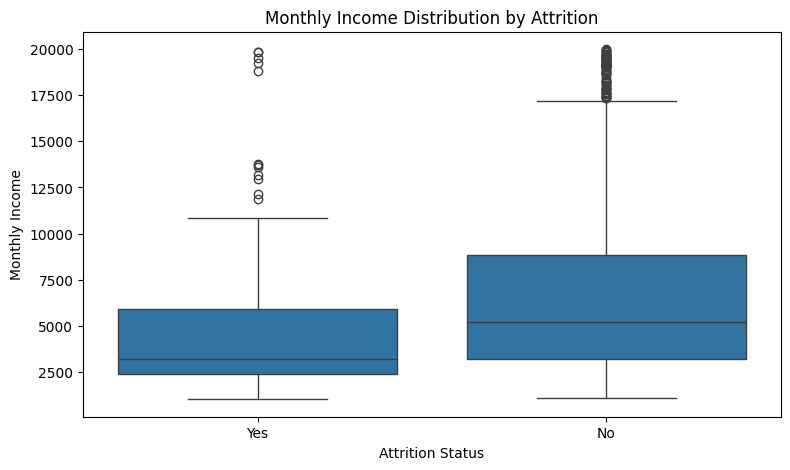

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Monthly Income")

plt.show()

In [12]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56+"
    ]
)

In [13]:
age_analysis = df.groupby(
    "AgeGroup",
    observed=True
).agg(
    Total_Employees=("EmployeeNumber", "count"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

age_analysis["Attrition_Rate"] = (
    age_analysis["Employees_Left"] /
    age_analysis["Total_Employees"]
) * 100

age_analysis.round(2)

,Total_Employees,Employees_Left,Attrition_Rate
AgeGroup,,,
18-25,123,44,35.77
26-35,606,116,19.14
36-45,468,43,9.19
46-55,226,26,11.50
56+,47,8,17.02


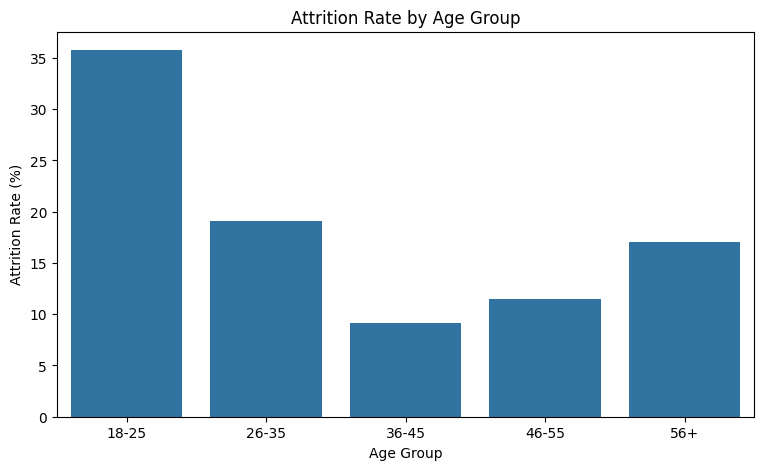

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_analysis.reset_index(),
    x="AgeGroup",
    y="Attrition_Rate"
)

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")

plt.show()

In [15]:
df["TenureGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 1, 3, 5, 10, 100],
    labels=[
        "0-1 Years",
        "2-3 Years",
        "4-5 Years",
        "6-10 Years",
        "10+ Years"
    ]
)

In [16]:
tenure_analysis = df.groupby(
    "TenureGroup",
    observed=True
).agg(
    Total_Employees=("EmployeeNumber", "count"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

tenure_analysis["Attrition_Rate"] = (
    tenure_analysis["Employees_Left"] /
    tenure_analysis["Total_Employees"]
) * 100

tenure_analysis.round(2)

,Total_Employees,Employees_Left,Attrition_Rate
TenureGroup,,,
0-1 Years,215,75,34.88
2-3 Years,255,47,18.43
4-5 Years,306,40,13.07
6-10 Years,448,55,12.28
10+ Years,246,20,8.13


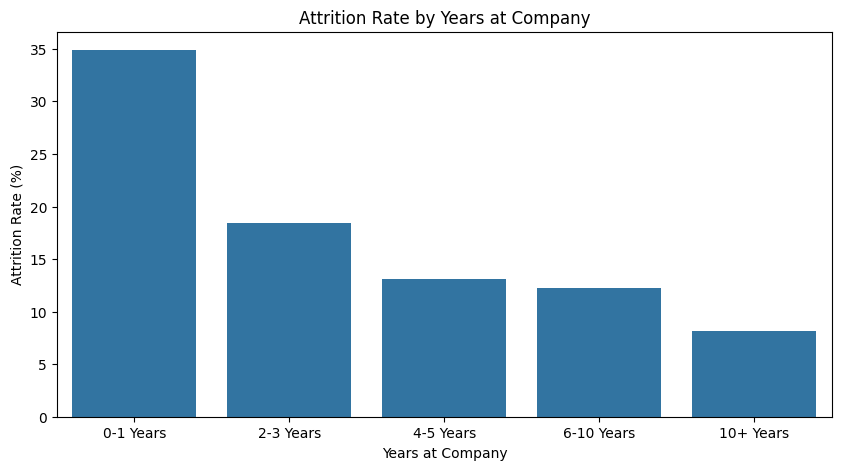

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tenure_analysis.reset_index(),
    x="TenureGroup",
    y="Attrition_Rate"
)

plt.title("Attrition Rate by Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")

plt.show()

In [18]:
jobrole_analysis = df.groupby("JobRole").agg(
    Total_Employees=("EmployeeNumber", "count"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

jobrole_analysis["Attrition_Rate"] = (
    jobrole_analysis["Employees_Left"] /
    jobrole_analysis["Total_Employees"]
) * 100

jobrole_analysis = jobrole_analysis.sort_values(
    by="Attrition_Rate",
    ascending=False
)

jobrole_analysis.round(2)

,Total_Employees,Employees_Left,Attrition_Rate
JobRole,,,
Sales Representative,83,33,39.76
Laboratory Technician,259,62,23.94
Human Resources,52,12,23.08
Sales Executive,326,57,17.48
Research Scientist,292,47,16.10
Manufacturing Director,145,10,6.90
Healthcare Representative,131,9,6.87
Manager,102,5,4.90
Research Director,80,2,2.50


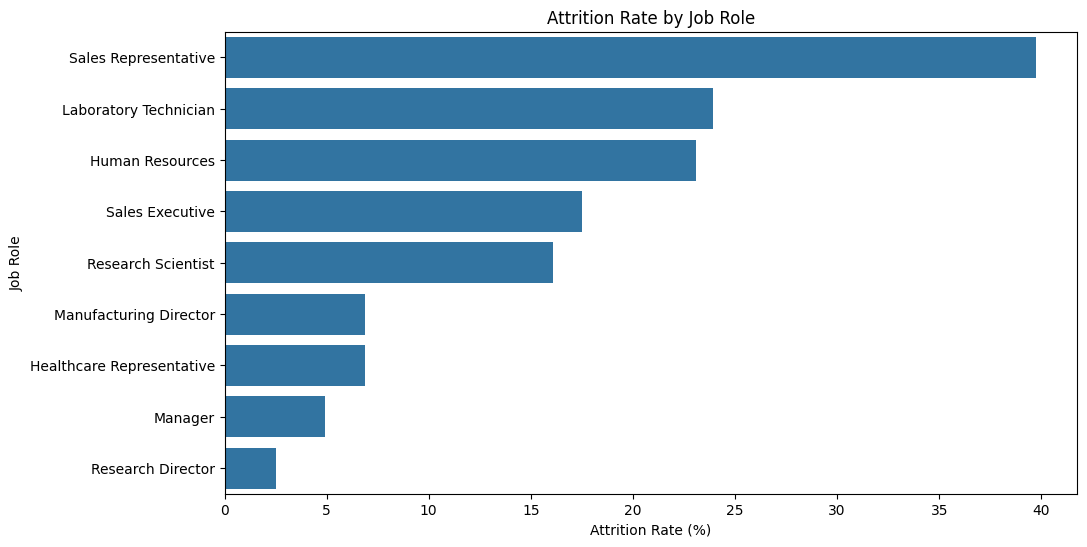

In [19]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=jobrole_analysis.reset_index(),
    x="Attrition_Rate",
    y="JobRole"
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

plt.show()

In [20]:
import sqlite3

conn = sqlite3.connect("../sql/hr_analytics.db")

df.to_sql(
    "employees",
    conn,
    if_exists="replace",
    index=False
)

conn.close()

print("Database created successfully!")

Database created successfully!
